# **06 - Results**

Runs after running notebooks 01-05. It only reads the per-passage caches from `RESULTS_DIR` and rebuilds every table and figure of the original notebook (01-05)

In [ ]:
# Restart after running this cell.
!pip install -q "transformers==4.36.2" selfcheckgpt sentencepiece "accelerate>=0.26,<1.0" "bitsandbytes>=0.43.0"
!python -m spacy download en_core_web_sm -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
sentence-transformers 5.7.0 requires tokenizers>=0.19, but you have tokenizers 0.15.2 which is incompatible.
sentence-transformers 5.7.0 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.36.2 which is incompatible.
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to 

In [ ]:
import os, sys
try:
    from google.colab import drive
    drive.mount('/content/drive')
    RESULTS_DIR = "/content/drive/MyDrive/selfcheckgpt_replication_results"
except ImportError:                      # running outside Colab
    RESULTS_DIR = "./selfcheckgpt_results"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.environ["SC_RESULTS_DIR"] = RESULTS_DIR
if RESULTS_DIR not in sys.path: sys.path.insert(0, RESULTS_DIR)
try:
    from sc_common import *            # shared config, dataset, metrics, cache helpers 
except ModuleNotFoundError:
    raise FileNotFoundError(f"Upload sc_common.py into {RESULTS_DIR} first.")
describe_device(); ram("after setup")

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/evaluation-00000-of-00001-e91191b8f(…):   0%|          | 0.00/2.56M [00:00<?, ?B/s]

Generating evaluation split:   0%|          | 0/238 [00:00<?, ? examples/s]

Using device: cpu
Results / caches -> /content/drive/MyDrive/selfcheckgpt_replication_results
[RAM after setup] this process 0.5 GB | system used 1.2 / 12.7 GB


# **Replication results of original work**

## Dataset and dataset statistics (paper Table 1, Fig. 4)

,quantity,this notebook,paper
0,# passages,238,238
1,# sentences,1908,1908
2,# major-inaccurate sentences,761,761
3,# minor-inaccurate sentences,631,631
4,# accurate sentences,516,516
5,# non-factual* passages,206,206
6,# sentences in non-factual* passages,1632,1632


Random-guess AUC-PR from label prevalence: {'NonFact': np.float64(72.96), 'NonFact*': np.float64(29.72), 'Factual': np.float64(27.04)}   (paper: NonFact 72.96, NonFact* 29.72, Factual 27.04)


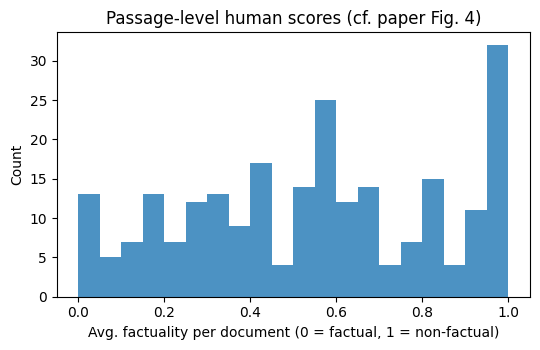

In [ ]:
# Table 1 / Fig. 4 
all_lab  = np.concatenate([HUMAN[i] for i in ALL_IDS])
star_ids = [i for i in ALL_IDS if HUMAN[i].mean() < 0.99]            # passages that are NOT total hallucinations
star_lab = np.concatenate([HUMAN[i] for i in star_ids])

stats = pd.DataFrame([
    ("# passages",                          len(rows),                       238),
    ("# sentences",                         len(all_lab),                    1908),
    ("# major-inaccurate sentences",        int((all_lab == 1.0).sum()),     761),
    ("# minor-inaccurate sentences",        int((all_lab == 0.5).sum()),     631),
    ("# accurate sentences",                int((all_lab == 0.0).sum()),     516),
    ("# non-factual* passages",             len(star_ids),                   206),
    ("# sentences in non-factual* passages", len(star_lab),                  1632),
], columns=["quantity", "this notebook", "paper"])
display(stats)

RANDOM_ALL = {"NonFact":  100 * (all_lab > 0.499).mean(),
              "NonFact*": 100 * (star_lab > 0.99).mean(),
              "Factual":  100 * (all_lab < 0.499).mean()}
print("Random-guess AUC-PR from label prevalence:", {k: round(v, 2) for k, v in RANDOM_ALL.items()},
      "  (paper: NonFact 72.96, NonFact* 29.72, Factual 27.04)")

plt.figure(figsize=(5.5, 3.6))
plt.hist([HUMAN[i].mean() for i in ALL_IDS], bins=20, color="tab:blue", alpha=0.8)
plt.xlabel("Avg. factuality per document (0 = factual, 1 = non-factual)"); plt.ylabel("Count")
plt.title("Passage-level human scores (cf. paper Fig. 4)")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig4_passage_factuality_hist.png"), dpi=150); plt.show()

## Evaluation framework

* **Sentence level (AUC-PR, x100)**, three detection tasks, all scored with the SelfCheckGPT inconsistency score `s` (higher = more likely hallucinated):
  * *NonFact*: positives = minor- or major-inaccurate sentences, score `s`
  * *NonFact\**: only passages that are not total hallucinations; positives = major-inaccurate sentences, score `s`
  * *Factual*: positives = accurate sentences, score `-s` (the paper uses `1 - s`; the ranking is identical)
* **Passage level**: passage score = mean of its sentence scores (for the n-gram *Avg* variants: mean over all tokens, as in the paper); human score = mean of the sentence labels (0 / 0.5 / 1). Reported as Pearson and Spearman correlation (x100); positive = good, because both quantities increase with hallucination.

In [ ]:
oracle = {i: HUMAN[i].copy() for i in IDS}
rng = np.random.default_rng(SEED)
randsc = {i: rng.random(len(HUMAN[i])) for i in IDS}
print("oracle scorer:", {k: round(v, 2) for k, v in evaluate(oracle).items() if k != "n_passages"})
print("random scorer:", {k: round(v, 2) for k, v in evaluate(randsc).items() if k != "n_passages"})
print("label-prevalence baseline:", {k: round(v, 2) for k, v in random_baseline(IDS).items()})

# worked examples 
y = [1, 0, 1, 0, 1]; s = [0.9, 0.2, 0.8, 0.4, 0.7]
x = [0.85, 0.30, 0.60, 0.15, 0.70]; f = [0.20, 0.90, 0.55, 0.95, 0.40]
print(f"proposal AUC-PR example -> {auc_pr(y, s):.3f} (expected 1.000);   proposal PCC example -> r = {pearsonr(x, f)[0]:.4f} (expected about -0.99)")

oracle scorer: {'NonFact': np.float64(100.0), 'NonFact*': np.float64(100.0), 'Factual': np.float64(100.0), 'Pearson': np.float64(100.0), 'Spearman': np.float64(100.0)}
random scorer: {'NonFact': np.float64(72.66), 'NonFact*': np.float64(29.21), 'Factual': np.float64(26.3), 'Pearson': np.float64(-13.17), 'Spearman': np.float64(-13.84)}
label-prevalence baseline: {'NonFact': 72.96, 'NonFact*': 29.72, 'Factual': 27.04}
proposal AUC-PR example -> 1.000 (expected 1.000);   proposal PCC example -> r = -0.9886 (expected about -0.99)


## Load the cached scores of every variant

Nothing is computed here: each variant is read from the cache written by notebooks 01-05.

In [4]:
RES_MAIN, SENT_MAIN, PASS_MAIN = {}, {}, {}    # Table 2: metrics / sentence scores / passage scores per method
RES_WIKI, RES_QA, RES_NGRAM = {}, {}, {}       # Table 3 / Table 5 / Table 7
MATS = {"bertscore": {}, "nli": {}, "prompt": {}}   # variant -> evidence -> {passage_id: sentences x samples matrix}
QCACHE = {}                                    # evidence -> {passage_id: per-sentence list of cached MQAG questions}
NGRAM_SCORES = {}                              # (n, evidence) -> {passage_id: {...}}

def register_main(name, sent_scores, passage_scores=None):
    RES_MAIN[name] = evaluate(sent_scores, passage_scores)
    SENT_MAIN[name], PASS_MAIN[name] = sent_scores, passage_scores
    print(name, {k: round(v, 2) for k, v in RES_MAIN[name].items()})

def ngram_eval(n, kind, evidence="samples"):
    d = NGRAM_SCORES[(n, evidence)]
    return evaluate({i: v[kind] for i, v in d.items()}, {i: v["doc_" + kind] for i, v in d.items()}), \
           {i: v[kind] for i, v in d.items()}, {i: v["doc_" + kind] for i, v in d.items()}

def sanitize_ngram(d):
    for key in ("avg", "max"):
        allv = np.concatenate([v[key] for v in d.values()])
        cap = allv[np.isfinite(allv)].max()
        n_bad = int((~np.isfinite(allv)).sum())
        for v in d.values():
            v[key] = np.where(np.isfinite(v[key]), v[key], cap)
        if n_bad: print(f"  replaced {n_bad} non-finite '{key}' scores with {cap:.2f}")
    for key in ("doc_avg", "doc_max"):
        vals = np.array([v[key] for v in d.values()])
        cap = vals[np.isfinite(vals)].max()
        for v in d.values():
            if not np.isfinite(v[key]): v[key] = cap

# ---- n-gram ----
orders = [1, 2, 3, 4, 5] if RUN_NGRAM_ORDERS else [1]
for n in orders:
    d = load_complete(f"ngram{n}_samples", IDS)
    if d is not None: NGRAM_SCORES[(n, "samples")] = d
if RUN_WIKIBIO_EVIDENCE:
    d = load_complete("ngram1_wiki", IDS)
    if d is not None: NGRAM_SCORES[(1, "wiki")] = d
for k_, d_ in NGRAM_SCORES.items():
    print("sanitizing", k_); sanitize_ngram(d_)
for (n, ev) in list(NGRAM_SCORES):
    if ev != "samples": continue
    for kind, label in (("avg", "Avg(-logp)"), ("max", "Max(-logp)")):
        RES_NGRAM[f"{label} {n}-gram"] = ngram_eval(n, kind)[0]
if (1, "samples") in NGRAM_SCORES:
    m, s, p = ngram_eval(1, "max"); register_main("SelfCheck-Unigram (max)", s, p)
if (1, "wiki") in NGRAM_SCORES:
    RES_WIKI["WikiBio+Unigram (max)"] = ngram_eval(1, "max", "wiki")[0]

# ---- BERTScore ----
d = load_complete("bertscore_samples", IDS)
if d is not None:
    MATS["bertscore"]["samples"] = d
    register_main("SelfCheck-BERTScore", scores_from_matrices("bertscore", d))
if RUN_WIKIBIO_EVIDENCE:
    d = load_complete("bertscore_wiki", IDS)
    if d is not None:
        MATS["bertscore"]["wiki"] = d
        RES_WIKI["WikiBio+BERTScore"] = evaluate(scores_from_matrices("bertscore", d))

# ---- NLI ----
d = load_complete("nli_samples", IDS)
if d is not None:
    MATS["nli"]["samples"] = d
    register_main("SelfCheck-NLI", scores_from_matrices("nli", d))
    y, s = task_arrays(SENT_MAIN["SelfCheck-NLI"])["NonFact"]
    print(f"NonFact: trapezoidal AUC-PR (paper protocol) = {100 * auc_pr(y, s):.2f}   |   average_precision_score = {100 * average_precision_score(y, s):.2f}")
    r, M = rows[IDS[0]], d[IDS[0]]
    for sent, sc, lab in list(zip(r["gpt3_sentences"], M.mean(axis=1), r["annotation"]))[:5]:
        print(f"[{sc:.2f}] ({lab}) {sent[:90]}")
if RUN_WIKIBIO_EVIDENCE:
    d = load_complete("nli_wiki", IDS)
    if d is not None:
        MATS["nli"]["wiki"] = d
        RES_WIKI["WikiBio+NLI"] = evaluate(scores_from_matrices("nli", d))

# ---- MQAG / QA ----
d = load_complete("mqag_samples", MQAG_IDS)
if d is not None:
    QCACHE["samples"] = d
    sc, empty = mqag_scores(d)
    print(f"sentences without any valid generated question (scored 0.5): {empty}")
    register_main("SelfCheck-QA", sc)
    for label, method in (("QA SimpleCount", "counting"), ("QA +Bayes", "bayes"), ("QA +Bayes+alpha", "bayes_with_alpha")):
        RES_QA[label] = evaluate(mqag_scores(d, method=method)[0])
if RUN_WIKIBIO_EVIDENCE:
    d = load_complete("mqag_wiki", MQAG_IDS)
    if d is not None:
        QCACHE["wiki"] = d
        RES_WIKI["WikiBio+QA"] = evaluate(mqag_scores(d)[0])

# ---- Prompt ----
d = load_complete(f"prompt_{PROMPT_SLUG}_samples", PROMPT_IDS)
if d is not None:
    MATS["prompt"]["samples"] = d
    register_main(f"SelfCheck-Prompt ({PROMPT_NAME})", scores_from_matrices("prompt", d))
if RUN_WIKIBIO_EVIDENCE:
    d = load_complete(f"prompt_{PROMPT_SLUG}_wiki", PROMPT_IDS)
    if d is not None:
        MATS["prompt"]["wiki"] = d
        RES_WIKI[f"WikiBio+Prompt ({PROMPT_NAME})"] = evaluate(scores_from_matrices("prompt", d))


sanitizing (1, 'samples')
sanitizing (2, 'samples')
  replaced 5 non-finite 'avg' scores with 8.11
  replaced 5 non-finite 'max' scores with 8.35
sanitizing (3, 'samples')
  replaced 9 non-finite 'avg' scores with 8.23
  replaced 9 non-finite 'max' scores with 8.35
sanitizing (4, 'samples')
  replaced 12 non-finite 'avg' scores with 8.25
  replaced 12 non-finite 'max' scores with 8.35
sanitizing (5, 'samples')
  replaced 13 non-finite 'avg' scores with 8.25
  replaced 13 non-finite 'max' scores with 8.35
sanitizing (1, 'wiki')
SelfCheck-Unigram (max) {'NonFact': np.float64(85.62), 'NonFact*': np.float64(41.03), 'Factual': np.float64(58.43), 'Pearson': np.float64(64.72), 'Spearman': np.float64(64.91), 'n_passages': 238}
SelfCheck-BERTScore {'NonFact': np.float64(81.2), 'NonFact*': np.float64(45.27), 'Factual': np.float64(43.47), 'Pearson': np.float64(57.34), 'Spearman': np.float64(54.41), 'n_passages': 238}
SelfCheck-NLI {'NonFact': np.float64(92.5), 'NonFact*': np.float64(45.17), 'Fact

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

sentences without any valid generated question (scored 0.5): 0
SelfCheck-QA {'NonFact': np.float64(82.43), 'NonFact*': np.float64(36.78), 'Factual': np.float64(41.62), 'Pearson': np.float64(68.4), 'Spearman': np.float64(69.48), 'n_passages': 20}
SelfCheck-Prompt (Mistral-7B-Instruct-v0.2) {'NonFact': np.float64(92.19), 'NonFact*': np.float64(46.76), 'Factual': np.float64(63.68), 'Pearson': np.float64(77.95), 'Spearman': np.float64(76.11), 'n_passages': 30}


# **Results**

## Table 2 - sentence-level AUC-PR and passage-level correlation

In [5]:
PROMPT_LABEL = f"SelfCheck-Prompt ({PROMPT_NAME})" if "samples" in MATS["prompt"] else None
random_row = {"Random (label prevalence)": {**random_baseline(IDS), "Pearson": np.nan, "Spearman": np.nan, "n_passages": len(IDS)}}
ref_main = {**PAPER_T2}
if PROMPT_LABEL:
    ref_main[PROMPT_LABEL] = README_PROMPT.get(PROMPT_NAME, PAPER_PROMPT_CHATGPT)
ordered = {k: RES_MAIN[k] for k in ["SelfCheck-BERTScore", "SelfCheck-QA", "SelfCheck-Unigram (max)", "SelfCheck-NLI", PROMPT_LABEL] if k in RES_MAIN}
ref_main["Random (label prevalence)"] = ("paper Table 2", (72.96, 29.72, 27.04, None, None))
TABLE2 = show_comparison({**random_row, **ordered}, ref_main, "Replication of Table 2 (AUC-PR x100 / correlation x100):")
TABLE2.to_csv(os.path.join(RESULTS_DIR, "table2_main_results.csv"), index=False)

Replication of Table 2 (AUC-PR x100 / correlation x100):


Method,Source,NonFact,NonFact*,Factual,Pearson,Spearman,n_passages
Random (label prevalence),this notebook,72.96,29.72,27.04,-,-,238.000000
,paper Table 2,72.96,29.72,27.04,-,-,nan
,difference (ours - ref),-0.00,-0.00,0.00,-,-,nan
SelfCheck-BERTScore,this notebook,81.20,45.27,43.47,57.34,54.41,238.000000
,paper Table 2,81.96,45.96,44.23,58.18,55.90,nan
,difference (ours - ref),-0.76,-0.69,-0.76,-0.84,-1.49,nan
SelfCheck-QA,this notebook,82.43,36.78,41.62,68.40,69.48,20.000000
,paper Table 2,84.26,40.06,48.14,61.07,59.29,nan
,difference (ours - ref),-1.83,-3.28,-6.52,7.33,10.19,nan
SelfCheck-Unigram (max),this notebook,85.62,41.03,58.43,64.72,64.91,238.000000


## Fig. 5 - precision-recall curves, Fig. 6 / 10 - passage-level scatter plots

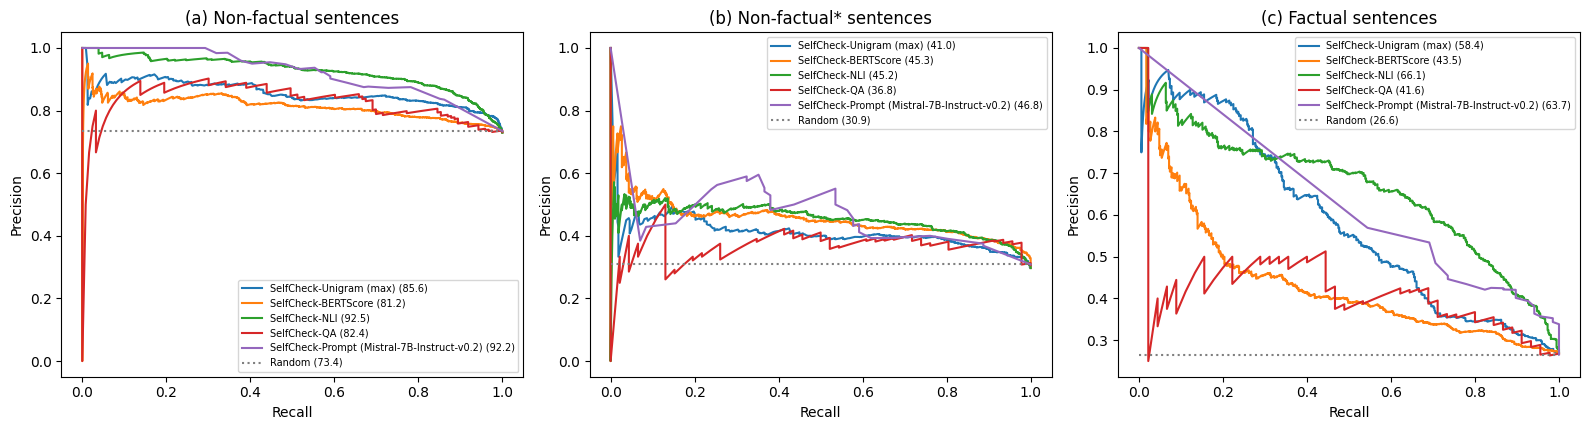

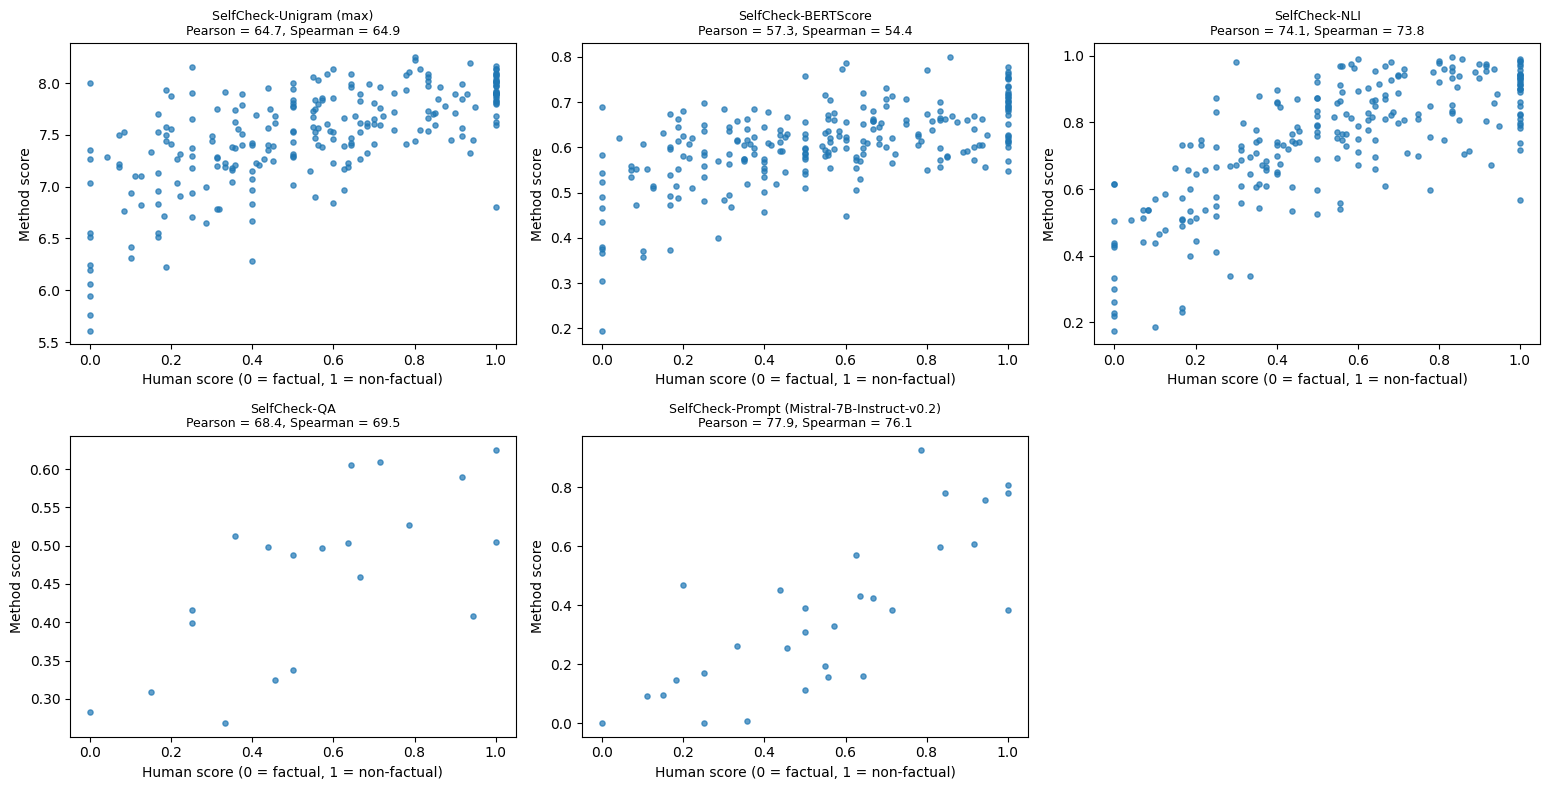

In [6]:
if SENT_MAIN:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    titles = {"NonFact": "(a) Non-factual sentences", "NonFact*": "(b) Non-factual* sentences", "Factual": "(c) Factual sentences"}
    for ax, task in zip(axes, ["NonFact", "NonFact*", "Factual"]):
        prevalence = None
        for name, sc in SENT_MAIN.items():
            y, s = task_arrays(sc)[task]
            P, R, _ = precision_recall_curve(y, s)
            ax.plot(R, P, label=f"{name} ({100 * auc(R, P):.1f})"); prevalence = y.mean()
        ax.hlines(prevalence, 0, 1, colors="grey", linestyles="dotted", label=f"Random ({100 * prevalence:.1f})")
        ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title(titles[task]); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig5_pr_curves.png"), dpi=150); plt.show()

    names = list(SENT_MAIN)
    cols = min(3, len(names)); nrows = int(np.ceil(len(names) / cols))
    fig, axes = plt.subplots(nrows, cols, figsize=(5.2 * cols, 4 * nrows), squeeze=False)
    for ax, name in zip(axes.ravel(), names):
        p, h = passage_arrays(SENT_MAIN[name], PASS_MAIN[name])
        ax.scatter(h, p, s=14, alpha=0.7)
        ax.set_xlabel("Human score (0 = factual, 1 = non-factual)"); ax.set_ylabel("Method score")
        ax.set_title(f"{name}\nPearson = {100 * pearsonr(p, h)[0]:.1f}, Spearman = {100 * spearmanr(p, h)[0]:.1f}", fontsize=9)
    for ax in axes.ravel()[len(names):]: ax.axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig6_fig10_passage_scatter.png"), dpi=150); plt.show()

## Table 5 - QA scoring variants, Table 7 - n-gram orders

In [7]:
if RES_QA:
    show_comparison(RES_QA, PAPER_T5, "Table 5 - SelfCheckGPT-QA scoring rules (same generated questions for all three rows):").to_csv(os.path.join(RESULTS_DIR, "table5_qa_variants.csv"), index=False)
if RES_NGRAM:
    show_comparison(RES_NGRAM, PAPER_T7, "Table 7 - n-gram order and Avg / Max aggregation:").to_csv(os.path.join(RESULTS_DIR, "table7_ngram_orders.csv"), index=False)

Table 5 - SelfCheckGPT-QA scoring rules (same generated questions for all three rows):


Method,Source,NonFact,NonFact*,Factual,Pearson,Spearman,n_passages
QA SimpleCount,this notebook,83.98,43.09,51.54,72.65,67.44,20.000000
,paper Table 5,83.97,40.07,47.78,57.39,55.15,nan
,difference (ours - ref),0.01,3.02,3.76,15.26,12.29,nan
QA +Bayes,this notebook,83.93,40.09,49.07,72.43,68.42,20.000000
,paper Table 5,83.04,38.58,47.41,56.43,55.03,nan
,difference (ours - ref),0.89,1.51,1.66,16.00,13.39,nan
QA +Bayes+alpha,this notebook,82.43,36.78,41.62,68.40,69.48,20.000000
,paper Table 5,84.26,40.06,48.14,61.07,59.29,nan
,difference (ours - ref),-1.83,-3.28,-6.52,7.33,10.19,nan


Table 7 - n-gram order and Avg / Max aggregation:


Method,Source,NonFact,NonFact*,Factual,Pearson,Spearman,n_passages
Avg(-logp) 1-gram,this notebook,81.52,40.33,41.78,40.68,39.23,238.000000
,paper Table 7,81.52,40.33,41.76,40.68,39.22,nan
,difference (ours - ref),0.00,0.00,0.02,0.00,0.01,nan
Max(-logp) 1-gram,this notebook,85.62,41.03,58.43,64.72,64.91,238.000000
,paper Table 7,85.63,41.04,58.47,64.71,64.91,nan
,difference (ours - ref),-0.01,-0.01,-0.04,0.01,-0.00,nan
Avg(-logp) 2-gram,this notebook,83.22,44.20,52.89,52.20,53.83,238.000000
,paper Table 7,82.94,44.38,52.81,58.84,58.11,nan
,difference (ours - ref),0.28,-0.18,0.08,-6.64,-4.28,nan
Max(-logp) 2-gram,this notebook,85.46,39.28,58.37,60.17,61.17,238.000000


## Table 3 - evidence from the WikiBio paragraph 

In [8]:
if RES_WIKI:
    t3 = {}
    for base, wiki in (("SelfCheck-BERTScore", "WikiBio+BERTScore"), ("SelfCheck-QA", "WikiBio+QA"), ("SelfCheck-Unigram (max)", "WikiBio+Unigram (max)"),
                       ("SelfCheck-NLI", "WikiBio+NLI"), (PROMPT_LABEL, f"WikiBio+Prompt ({PROMPT_NAME})" if PROMPT_LABEL else None)):
        if base in RES_MAIN: t3[base] = RES_MAIN[base]
        if wiki in RES_WIKI: t3[wiki] = RES_WIKI[wiki]
    ref3 = dict(PAPER_T3)
    if PROMPT_LABEL:
        ref3[PROMPT_LABEL] = PAPER_T3["SelfCheck-Prompt (ChatGPT)"]; ref3[f"WikiBio+Prompt ({PROMPT_NAME})"] = PAPER_T3["WikiBio+Prompt (ChatGPT)"]
    show_comparison(t3, ref3, "Table 3 - SelfCheck samples vs. WikiBio reference evidence (the Prompt rows compare an open LLM with the paper's ChatGPT):").to_csv(os.path.join(RESULTS_DIR, "table3_wikibio_evidence.csv"), index=False)

Table 3 - SelfCheck samples vs. WikiBio reference evidence (the Prompt rows compare an open LLM with the paper's ChatGPT):


Method,Source,NonFact,NonFact*,Factual,Pearson,Spearman,n_passages
SelfCheck-BERTScore,this notebook,81.20,45.27,43.47,57.34,54.41,238.000000
,paper Table 3,81.96,45.96,44.23,58.18,55.90,nan
,difference (ours - ref),-0.76,-0.69,-0.76,-0.84,-1.49,nan
WikiBio+BERTScore,this notebook,80.45,39.82,47.91,58.03,54.63,238.000000
,paper Table 3,81.32,40.62,49.15,58.71,55.80,nan
,difference (ours - ref),-0.87,-0.80,-1.24,-0.68,-1.17,nan
SelfCheck-QA,this notebook,82.43,36.78,41.62,68.40,69.48,20.000000
,paper Table 3,84.26,40.06,48.14,61.07,59.29,nan
,difference (ours - ref),-1.83,-3.28,-6.52,7.33,10.19,nan
WikiBio+QA,this notebook,87.86,44.74,44.95,73.52,78.51,20.000000


## Fig. 7 / 8 - effect of the number of samples

Sentence scores for the first *N* samples (N = 1 ... 20) are computed from the cached per-sample matrices (and cached MQAG questions); only the unigram model is re-estimated

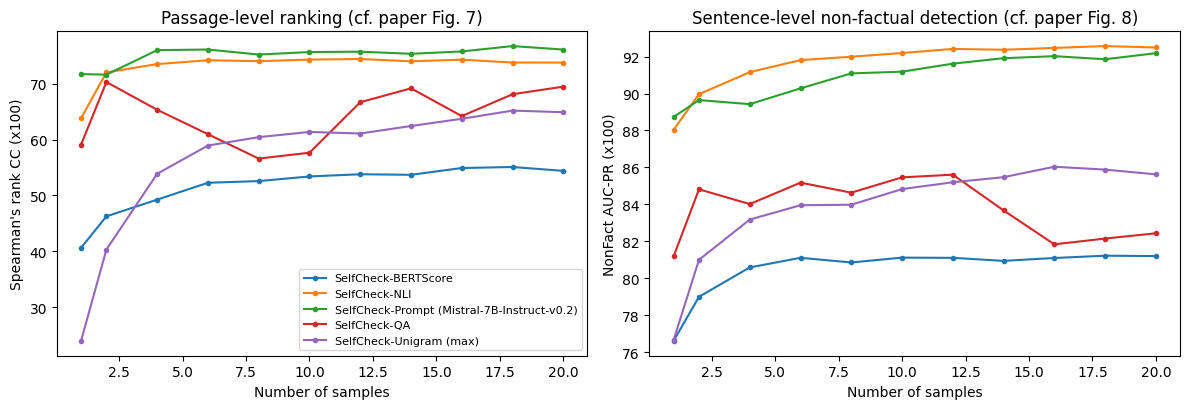

In [9]:
if RUN_SAMPLE_ABLATION and SENT_MAIN:
    curves = {}
    for variant, label in (("bertscore", "SelfCheck-BERTScore"), ("nli", "SelfCheck-NLI"), ("prompt", PROMPT_LABEL)):
        if "samples" in MATS[variant] and MATS[variant]["samples"]:
            curves[label] = [evaluate(scores_from_matrices(variant, MATS[variant]["samples"], n)) for n in NS]
    if QCACHE.get("samples"):
        curves["SelfCheck-QA"] = [evaluate(mqag_scores(QCACHE["samples"], n=n)[0]) for n in NS]
    uni_cache = load_complete("unigram_ablation", IDS)
    if uni_cache is not None:
        curves["SelfCheck-Unigram (max)"] = [evaluate({i: uni_cache[i][n] for i in IDS}) for n in NS]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for label, res in curves.items():
        axes[0].plot(NS, [r["Spearman"] for r in res], marker="o", ms=3, label=label)
        axes[1].plot(NS, [r["NonFact"] for r in res], marker="o", ms=3, label=label)
    axes[0].set_xlabel("Number of samples"); axes[0].set_ylabel("Spearman's rank CC (x100)"); axes[0].set_title("Passage-level ranking (cf. paper Fig. 7)")
    axes[1].set_xlabel("Number of samples"); axes[1].set_ylabel("NonFact AUC-PR (x100)");      axes[1].set_title("Sentence-level non-factual detection (cf. paper Fig. 8)")
    axes[0].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig7_fig8_num_samples.png"), dpi=150); plt.show()

    abl = pd.DataFrame([{"method": lab, "N": n, **{k: r[k] for k in METRICS}} for lab, res in curves.items() for n, r in zip(NS, res)])
    abl.to_csv(os.path.join(RESULTS_DIR, "num_samples_ablation.csv"), index=False)

## Save everything

In [ ]:
summary = {
    "config": {k: globals()[k] for k in ["SEED", "MAX_PASSAGES", "MQAG_MAX_PASSAGES", "PROMPT_MAX_PASSAGES", "MQAG_NUM_QUESTIONS", "MQAG_FP16", "LLM_BACKEND", "HF_LLM", "OPENAI_MODEL"]},
    "table2": {k: {m: (None if pd.isna(v) else round(float(v), 2)) for m, v in r.items()} for k, r in RES_MAIN.items()},
    "table3": {k: {m: (None if pd.isna(v) else round(float(v), 2)) for m, v in r.items()} for k, r in RES_WIKI.items()},
    "table5": {k: {m: (None if pd.isna(v) else round(float(v), 2)) for m, v in r.items()} for k, r in RES_QA.items()},
    "table7": {k: {m: (None if pd.isna(v) else round(float(v), 2)) for m, v in r.items()} for k, r in RES_NGRAM.items()},
}
with open(os.path.join(RESULTS_DIR, "summary.json"), "w") as f: json.dump(summary, f, indent=2)

# per-sentence scores of every method
sent_rows = []
for name, sc in SENT_MAIN.items():
    for i, arr in sc.items():
        for j, v in enumerate(arr):
            sent_rows.append({"method": name, "passage_id": i, "sentence_id": j, "score": float(v), "human_label": float(HUMAN[i][j])})
pd.DataFrame(sent_rows).to_csv(os.path.join(RESULTS_DIR, "sentence_scores_all_methods.csv"), index=False)
print("saved to", RESULTS_DIR, "->", sorted(f for f in os.listdir(RESULTS_DIR) if not f.startswith("cache_")))

saved to /content/drive/MyDrive/selfcheckgpt_replication_results -> ['01_ngram.ipynb', '02_bertscore.ipynb', '03_nli.ipynb', '04_mqag.ipynb', '05_prompt.ipynb', '06_results.ipynb', '__pycache__', 'fig4_passage_factuality_hist.png', 'fig5_pr_curves.png', 'fig6_fig10_passage_scatter.png', 'fig7_fig8_num_samples.png', 'num_samples_ablation.csv', 'sc_common.py', 'sentence_scores_all_methods.csv', 'summary.json', 'table2_main_results.csv', 'table3_wikibio_evidence.csv', 'table5_qa_variants.csv', 'table7_ngram_orders.csv']
